In [22]:
import scanpy as sc
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import time

Loading the Preprocessed PBMC Dataset

In [11]:
data = sc.datasets.pbmc3k_processed()
print(data)

AnnData object with n_obs × n_vars = 2638 × 1838
    obs: 'n_genes', 'percent_mito', 'n_counts', 'louvain'
    var: 'n_cells'
    uns: 'draw_graph', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_tsne', 'X_umap', 'X_draw_graph_fr'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'


In [9]:
print(data.obs)

                  n_genes  percent_mito  n_counts          louvain
index                                                             
AAACATACAACCAC-1      781      0.030178    2419.0      CD4 T cells
AAACATTGAGCTAC-1     1352      0.037936    4903.0          B cells
AAACATTGATCAGC-1     1131      0.008897    3147.0      CD4 T cells
AAACCGTGCTTCCG-1      960      0.017431    2639.0  CD14+ Monocytes
AAACCGTGTATGCG-1      522      0.012245     980.0         NK cells
...                   ...           ...       ...              ...
TTTCGAACTCTCAT-1     1155      0.021104    3459.0  CD14+ Monocytes
TTTCTACTGAGGCA-1     1227      0.009294    3443.0          B cells
TTTCTACTTCCTCG-1      622      0.021971    1684.0          B cells
TTTGCATGAGAGGC-1      454      0.020548    1022.0          B cells
TTTGCATGCCTCAC-1      724      0.008065    1984.0      CD4 T cells

[2638 rows x 4 columns]


In [10]:
print(data.var)

         n_cells
index           
TNFRSF4      155
CPSF3L       202
ATAD3C         9
C1orf86      501
RER1         608
...          ...
ICOSLG        34
SUMO3        570
SLC19A1       31
S100B         94
PRMT2        588

[1838 rows x 1 columns]


(a) Perform PCA as a first dimensionality reduction step and plot your results

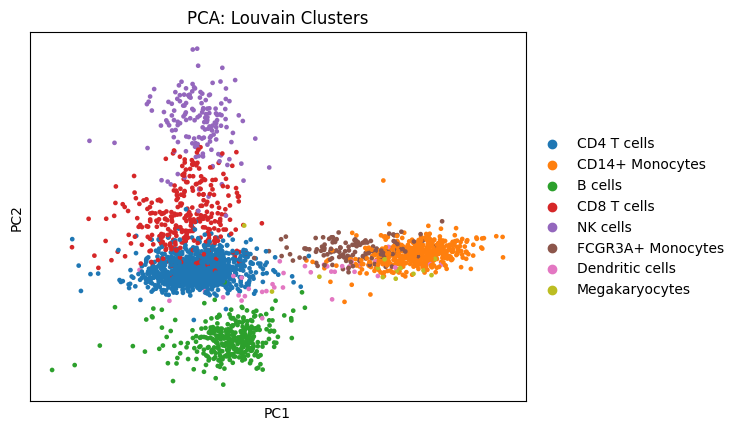

In [7]:
sc.tl.pca(data, svd_solver='arpack')
sc.pl.pca(data, color='louvain', title="PCA: Louvain Clusters")

Louvain Clustering: The plot overlays Louvain clusters to group similar cells.

1. Clear separation of clusters like B cells (green) and CD14+ Monocytes (orange), and NK cells indicating distinct transcriptional profiles.
2. CD4 and CD8 T cells (blue and red) are closely located, possibly reflecting shared lineage or overlapping expression profiles, as they are types of T lymphocytes in immune system.
3. Some mixing or overlap exists, indicates transitional states or technical noise.

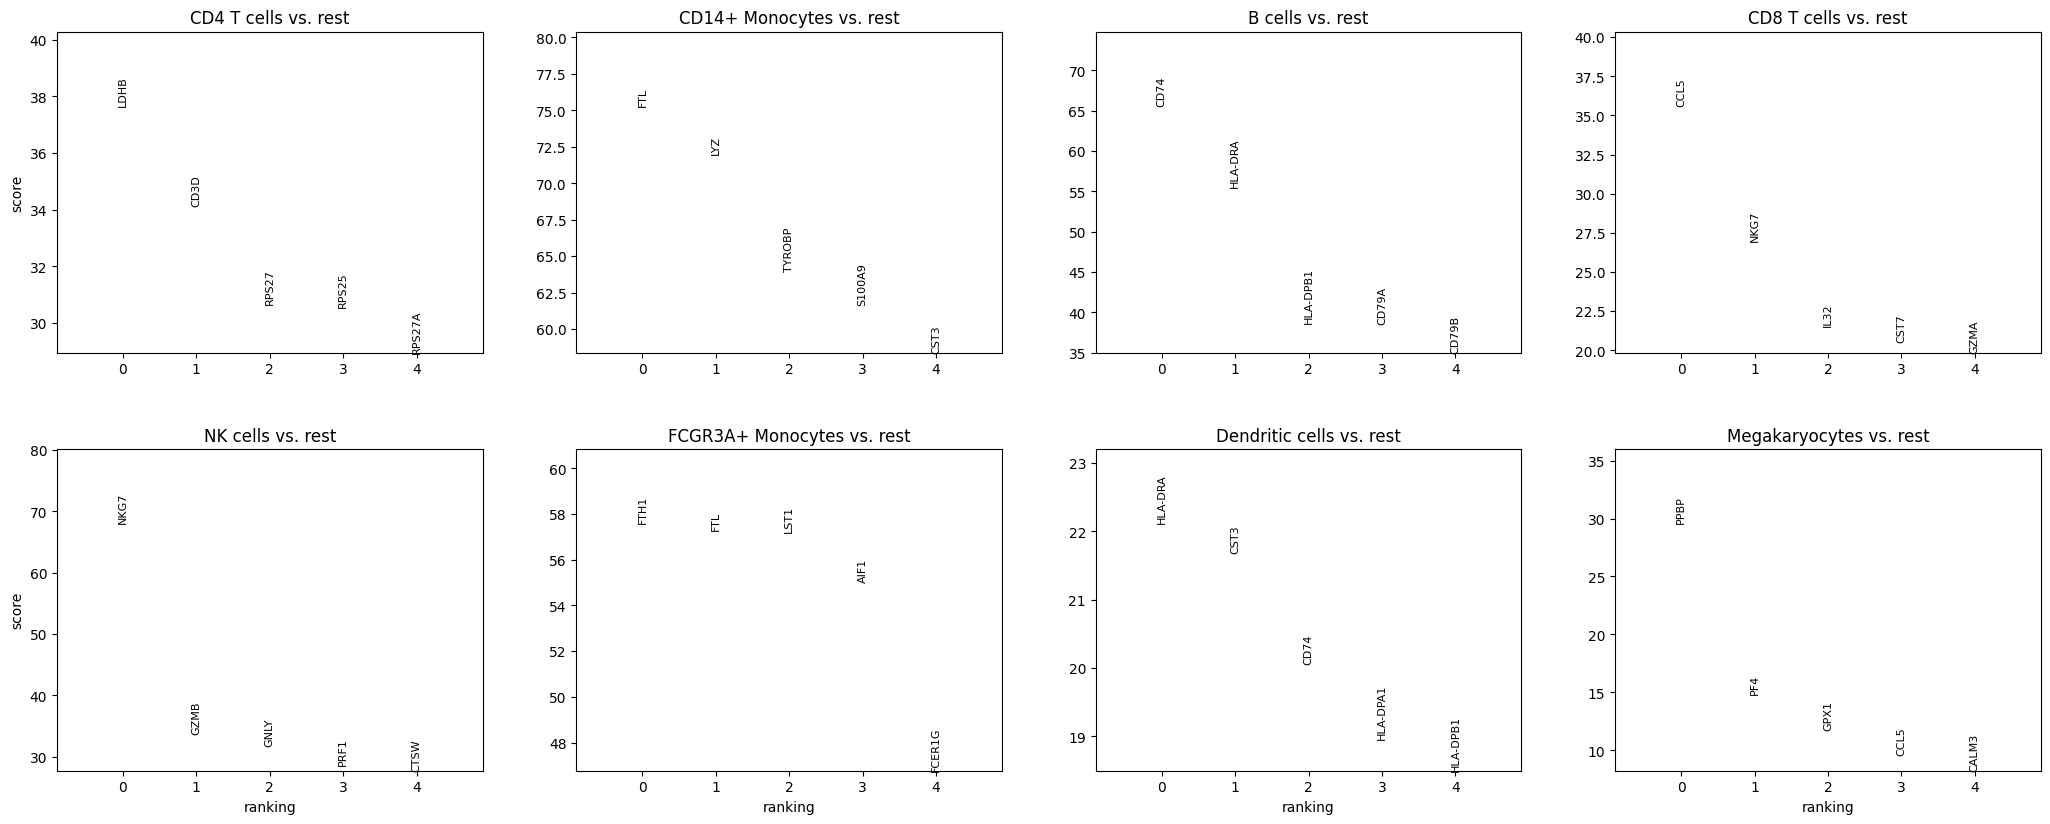

In [34]:
#top marker genes per cluster(cell type)
sc.tl.rank_genes_groups(data, 'louvain', method='t-test')
sc.pl.rank_genes_groups(data, n_genes=5, sharey=False)

(b) Run t-SNE with Different Perplexity Values

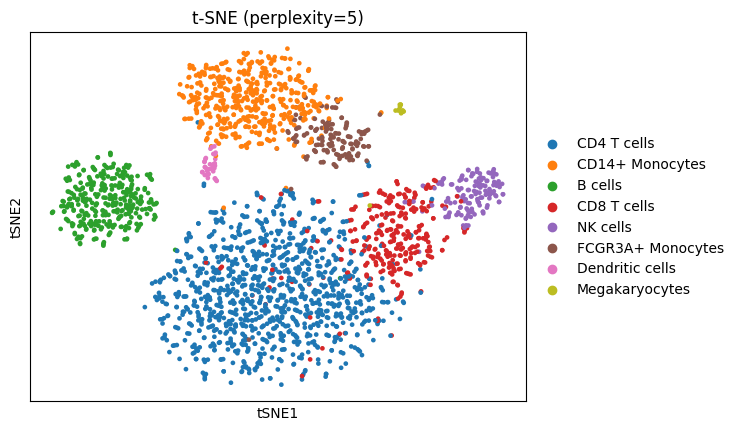

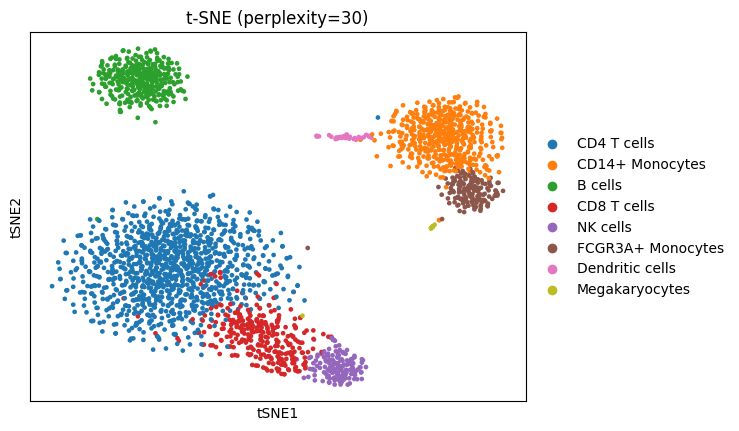

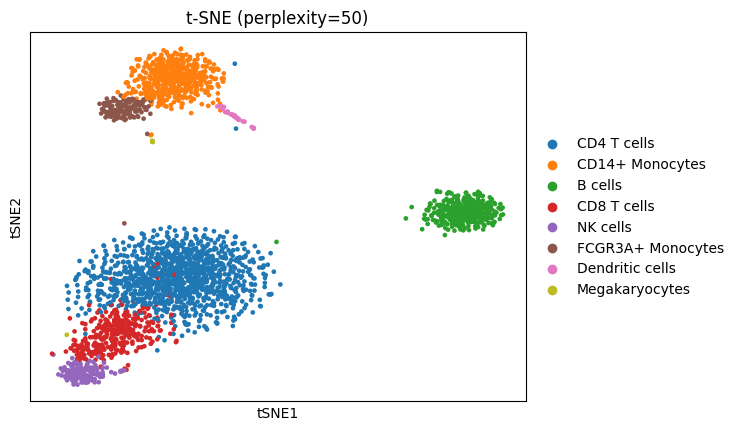

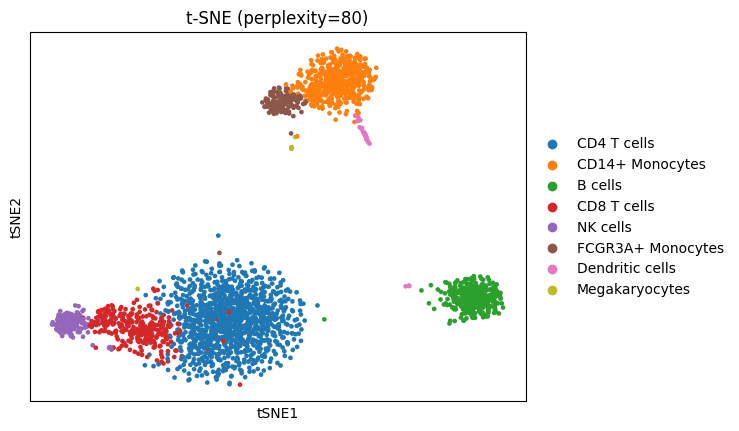

In [31]:
perplexities = [5, 30, 50, 80]
tsne_times = []

for perplexity in perplexities:
    start = time.time()
    sc.tl.tsne(data, perplexity=perplexity)
    end = time.time()

    runtime = end - start
    tsne_times.append((perplexity, runtime))

    sc.pl.tsne(data, color='louvain', title=f"t-SNE (perplexity={perplexity})")

Interpretation:

1. Perplexity= 5: t-SNE focuses on very local structure,and is sensitive to local noise results in over-segmented(overlapped) clusters and consequently some similar cells may appear as multiple clusters.
3. Perplexity= 30: A good balance of local and global structure in scRNA-seq data, results have few over-segmented clusters, ideally preserves the actual biological structure and distinct cell identities.
4. Perplexity= 50: Captured more global structure but chances are it oversimplified some clearly distinct clusters(i.e., between similar cell types like CD4 vs. CD8 T cells), results in undersegmentation.
5. Perplexity= 80: most global structure so far, clear under segmentation, multiple cell types groups together in a singnle cluster, clubbing dissimilar cell types together, worst for interpretation.

So far, Perplexity 30 shows the most meaningful clustering without distorting local or global relationships much

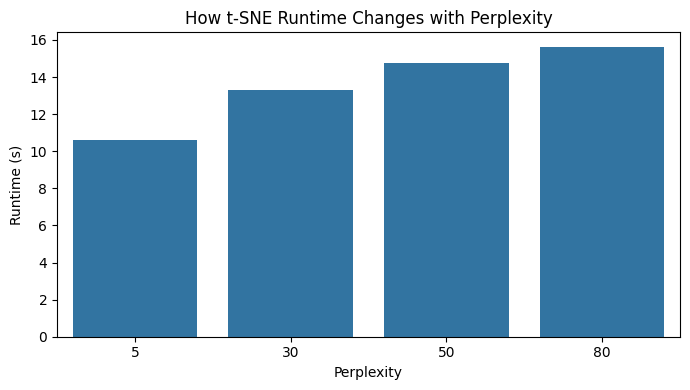

In [32]:
runtime_df = pd.DataFrame(tsne_times, columns=['Perplexity', 'Runtime (s)'])
plt.figure(figsize=(7, 4))
sns.barplot(data=runtime_df, x='Perplexity', y='Runtime (s)')
plt.title("How t-SNE Runtime Changes with Perplexity")
plt.tight_layout()
plt.show()

Runtime: Higher perplexity shows an increased runtime due to more complex optimization and further over-simplification of the data

(c) Run UMAP with different n_neighbors values, record the runtime for each run, and analyze how n_neighbors affects the visualization of cell types (using known marker genes). Plot your results.

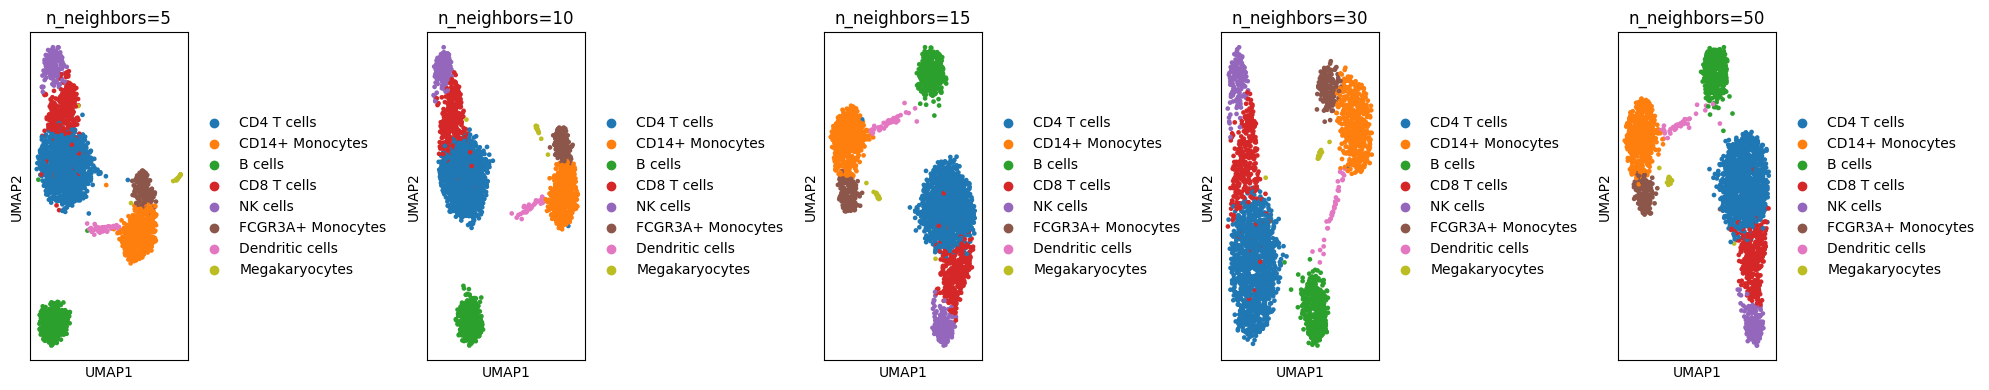


Marker gene expression in UMAP (n_neighbors=10):


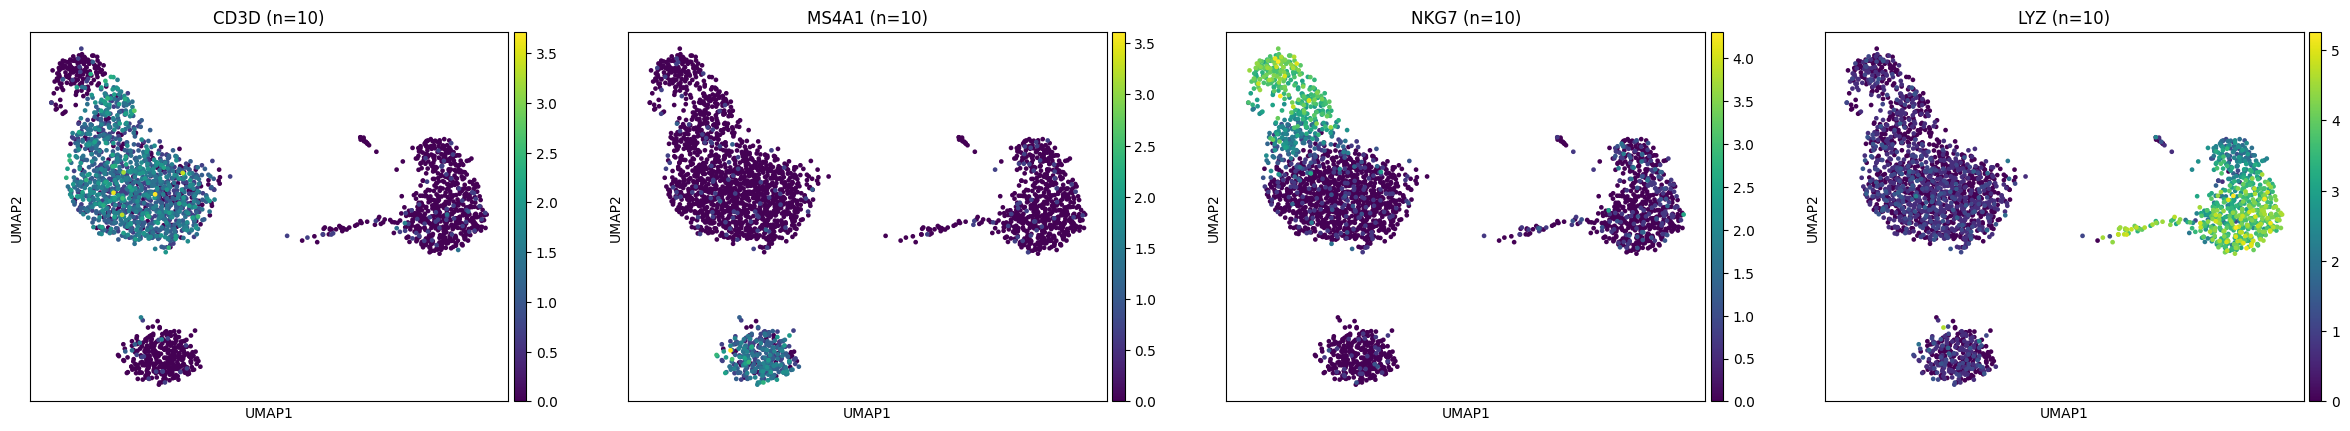


Marker gene expression in UMAP (n_neighbors=30):


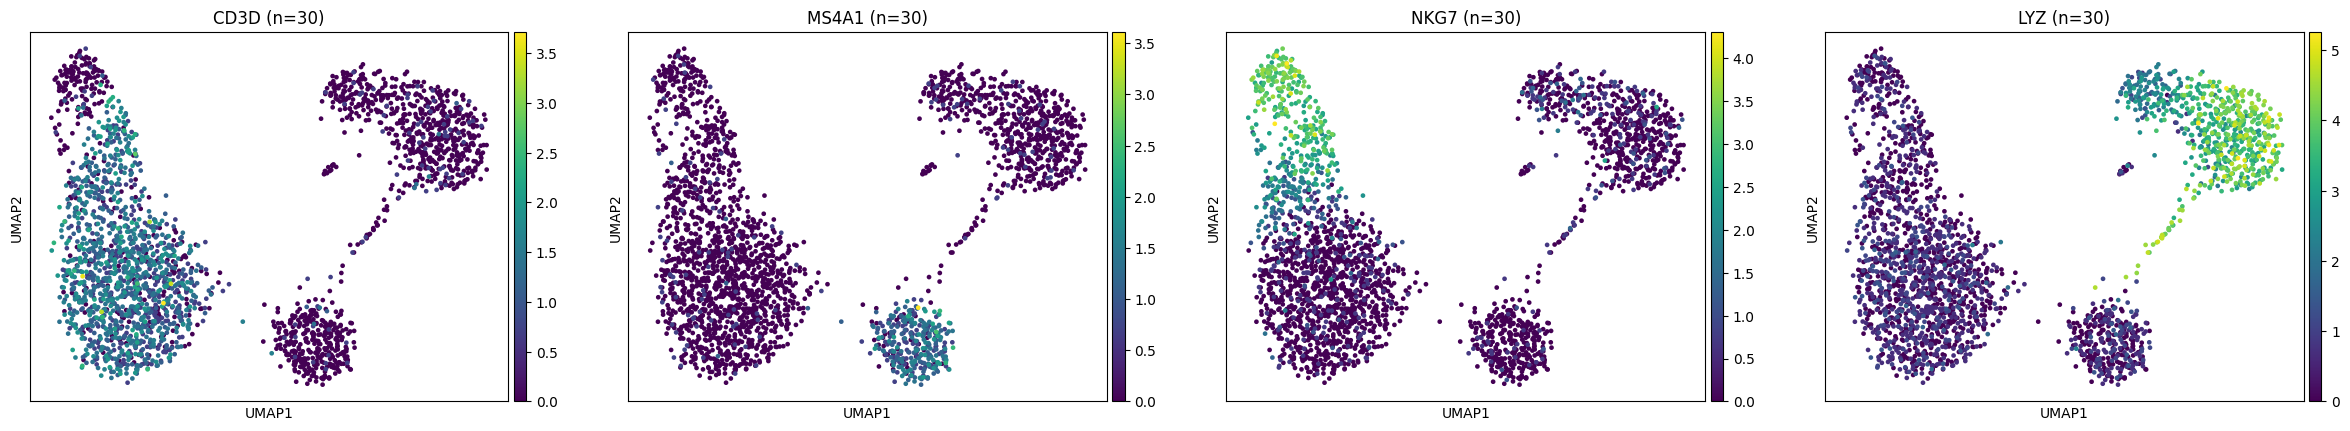


UMAP Runtimes:
n_neighbors=5: 4.03 seconds
n_neighbors=10: 5.37 seconds
n_neighbors=15: 6.33 seconds
n_neighbors=30: 8.01 seconds
n_neighbors=50: 9.38 seconds


In [37]:
#Code for for cell type and known immune cell marker genes
marker_genes = ['CD3D', 'MS4A1', 'NKG7', 'LYZ']  # T cells, B cells, NK cells, Monocytes
#chosen from the marker gene plots

n_neighbors_list = [5, 10, 15, 30, 50]
umap_results = {}
runtimes = {}
for n in n_neighbors_list:
    data_tmp = data.copy()
    start_time = time.time()
    
    sc.pp.neighbors(data_tmp, n_neighbors=n, use_rep='X_pca')
    sc.tl.umap(data_tmp)
    
    runtime = time.time() - start_time
    runtimes[n] = runtime
    umap_results[n] = data_tmp

#UMAPs colored by Louvain cluster
fig, axes = plt.subplots(1, len(n_neighbors_list), figsize=(4 * len(n_neighbors_list), 4))
for i, n in enumerate(n_neighbors_list):
    sc.pl.umap(umap_results[n], color='louvain', title=f'n_neighbors={n}', show=False, ax=axes[i])
plt.tight_layout()
plt.show()
#UMAPs colored by marker genes for 10 & 30
for n in [10, 30]:
    print(f"\nMarker gene expression in UMAP (n_neighbors={n}):")
    sc.pl.umap(umap_results[n], color=marker_genes, title=[f"{gene} (n={n})" for gene in marker_genes])

print("\nUMAP Runtimes:")
for n, t in runtimes.items():
    print(f"n_neighbors={n}: {t:.2f} seconds")


Interpretation:
Marker genes like CD3D (T cells), MS4A1 (B cells), NKG7 (NK cells), and LYZ (Monocytes) help identify distinct immune cell clusters in above UMAP plots
1. n_neighbors=5: Very localized with small tight cluster, overfits to local structure; less generalizable
2. n_neighbors=10: Shows somewhat a balanced cluster, almost all immune cell types are separatly clustered
3. n_neighbors=15: Good separation of major immune types, similar to n=10, however dendritic and megakaryotes are closely clutered but with a better spread hence might biologically interpretable
4. n_neighbors=30: Here we notice broader clusters, smoother transitions, they are less tight as compared to previous n values, but still a good cluter separation
5. n_neighbors=50: Showing a blend in clusters, again can result in underfitting, but we can use this for lineage discovery or high-level trends

Smaller values = sharper local separation (exaggerated differences).
Larger values = smooth transitions (hide fine-grained differences).
A moderate range (10–30) provides a good balance between clear separation and meaningful biological relationships.



(d) How do the parameter choices affect the visualization of the cell populations? Which method better preserves the relationships between different immune cell types known to exist in PBMCs? How do computation times compare between t-SNE and UMAP, and why might this matter for larger datasets?

1. t-SNE (Perplexity)-
Perplexity= 5: t-SNE focuses on very local structure,and is sensitive to local noise results in over-segmented(overlapped) clusters and consequently some similar cells may appear as multiple clusters.
Perplexity= 30: A good balance of local and global structure in scRNA-seq data, results have few over-segmented clusters, ideally preserves the actual biological structure and distinct cell identities.
Perplexity= 50: Captured more global structure but chances are it oversimplified some clearly distinct clusters(i.e., between similar cell types like CD4 vs. CD8 T cells), results in undersegmentation.
Perplexity= 80: most global structure so far, clear under segmentation, multiple cell types groups together in a singnle cluster, clubbing dissimilar cell types together, worst for interpretation.


- UMAP (n_neighbors)
n_neighbors=5: Very localized with small tight cluster, overfits to local structure; less generalizable
n_neighbors=10: Shows somewhat a balanced cluster, almost all immune cell types are separatly clustered
n_neighbors=15: Good separation of major immune types, similar to n=10, however dendritic and megakaryotes are closely clutered but with a better spread hence might biologically interpretable
n_neighbors=30: Here we notice broader clusters, smoother transitions, they are less tight as compared to previous n values, but still a good cluter separation
n_neighbors=50: Showing a blend in clusters, again can result in underfitting, but we can use this for lineage discovery or high-level trends


2. UMAP typically preserves global structure better as the immune cell types like T cells, B cells, Monocytes, and NK cells maintain consistent spatial relationships across clusters. Hence it is good for exploring gradients, lineages, or transitions in monocytes or t cells. Whereas t-SNE is better for local detail. It is excellent in sense of tight clustering of well-defined populations ( like B cells, NK cells, T cells etc) but they are poor at showing overall proximity or developmental relationships (e.g., CD4 and CD8 T cells may appear far apart even if biologically close).
Therefore, t-SNE seems good for local cluster separation and UMAP for global biological relations.

3. Computation time of UMAP is much faster, and it is efficient on large datasets.

### Task3
a- Clustering is an instance of unsupervised learning. --> True

b- In K-means clustering, we directly maximise the between-cluster-dissimilarity. --> False (minimize within cluster sum of squares)

c- In K-means clustering, we are guaranteed to find the global optimum if we re-run the clustering on the same data multiple times. --> False (converge to local minima) 

d- In hierarchical clustering, the height of the cut in a dendrogram controls the number of clusters obtained. --> True

e- In hierarchical clustering, the lower in the tree a fusion between groups occurs, the more similar the elements of the groups are to each other. --> True

f- In a dendrogram with 10 leafs (observations), there are 128 equivalent reorderings of the dendrogram. --> False (2^n-1 = 2^9 = 512 != 128)